# Superstore Profitability Analysis
### Why does profit lag behind sales, and where should the business act?

| | |
|---|---|
| **Role of this analysis** | Business / Data Analyst portfolio project |
| **Dataset** | Superstore orders, 10,194 order lines, Jan 2023 to Dec 2026, US only |
| **Tools** | Python, pandas, NumPy, matplotlib, seaborn |
| **Source file** | `data/123.xls` |

---
**Contents**
1. [Business problem and objectives](#1.-Business-problem-and-objectives)
2. [Setup and data loading](#2.-Setup-and-data-loading)
3. [Data quality and feature engineering](#3.-Data-quality-and-feature-engineering)
4. [Q1. Sales and profit trend](#4.-Q1.-Sales-and-profit-trend)
5. [Q2. Categories, sub-categories and regions](#5.-Q2.-Categories,-sub-categories-and-regions)
6. [Q3. Does discounting hurt profit?](#6.-Q3.-Does-discounting-hurt-profit?)
7. [Q4. Customers and segments](#7.-Q4.-Customers-and-segments)
8. [Q5. Does shipping matter?](#8.-Q5.-Does-shipping-matter?)
9. [Export processed data](#9.-Export-processed-data)
10. [Recommendations and limitations](#10.-Recommendations-and-limitations)

## Executive summary

Sales grew about **51%** between 2023 and 2026 (\$494K to \$746K), but the overall margin is only **12.6%**, and several parts of the business lose money while growing. Five findings explain most of the gap:

| # | Finding | Evidence |
|---|---------|----------|
| 1 | **Discounts above 20% always lose money** | Margin is 29.6% with no discount and negative from 21% upward; those lines lose about \$136K |
| 2 | **Furniture barely breaks even** | 2.6% margin vs about 17% for the other categories; Tables (-\$17.8K) and Bookcases (-\$3.6K) lose money |
| 3 | **Central region underperforms** | 7.9% margin vs 15.0% in the West, with a 24% average discount vs 11% |
| 4 | **Top customer by sales is unprofitable** | Sean Miller: \$25K sales, -\$2K profit; 20% of all customers cost money |
| 5 | **Shipping mode is not a profit driver** | Margins stay between 12.2% and 13.9% across all modes |

**Main recommendation:** cap discounts at 20%. Bringing the over-discounted lines to break-even would raise total profit by about **47%**.

## 1. Business problem and objectives

Leadership sees sales rising every year, but profit is not growing at the same rate. This analysis looks for **where margin is lost** and **what to change first**.

**Guiding questions**
1. How have sales and profit trended over time?
2. Which categories, sub-categories and regions make or lose money?
3. Does discounting hurt profit?
4. Who are the most valuable customers and segments?
5. Does shipping mode or delivery time matter?

## 2. Setup and data loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
df = pd.read_excel("data/123.xls")
df.head(10)

FileNotFoundError: [Errno 2] No such file or directory: 'data/123.xls'

## 3. Data quality and feature engineering

### 3.1 Structure and basic checks

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  str           
 2   Order Date      10194 non-null  datetime64[us]
 3   Ship Date       10194 non-null  datetime64[us]
 4   Ship Mode       10194 non-null  str           
 5   Customer ID     10194 non-null  str           
 6   Customer Name   10194 non-null  str           
 7   Segment         10194 non-null  str           
 8   Country/Region  10194 non-null  str           
 9   City            10194 non-null  str           
 10  State/Province  10194 non-null  str           
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  str           
 13  Product ID      10194 non-null  str           
 14  Category        10194 non-null  str           
 15  Sub-Category 

In [ ]:
df.duplicated().sum()


np.int64(0)

In [ ]:
df.describe()                      # look for negative or odd values


,Row ID,Order Date,Ship Date,Sales,Quantity,Discount,Profit
count,10194.000000,10194,10194,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,2025-04-29 11:48:25.002943,2025-05-03 10:52:45.626839,228.225854,3.791838,0.155385,28.673417
min,1.000000,2023-01-03 00:00:00,2023-01-07 00:00:00,0.444000,1.000000,0.000000,-6599.978000
25%,2549.250000,2024-05-14 00:00:00,2024-05-19 00:00:00,17.220000,2.000000,0.000000,1.760800
50%,5097.500000,2025-06-25 00:00:00,2025-06-28 00:00:00,53.910000,3.000000,0.200000,8.690000
75%,7645.750000,2026-05-14 00:00:00,2026-05-18 00:00:00,209.500000,5.000000,0.200000,29.297925
max,10194.000000,2026-12-30 00:00:00,2027-01-05 00:00:00,22638.480000,14.000000,0.800000,8399.976000
std,2942.898656,NaN,NaN,619.906839,2.228317,0.206249,232.465115


In [ ]:
# Validation checks
print('Duplicate rows         :', df.duplicated().sum())
print('Missing values         :', df.isna().sum().sum())
print('Ship date before order :', (df['Ship Date'] < df['Order Date']).sum())
print('Discount outside 0-1   :', ((df['Discount'] < 0) | (df['Discount'] > 1)).sum())
print('Date range             :', df['Order Date'].min().date(), 'to', df['Order Date'].max().date())

Duplicate rows         : 0
Missing values         : 0
Ship date before order : 0
Discount outside 0-1   : 0
Date range             : 2023-01-03 to 2026-12-30


**Result:** the data is clean. There are no duplicates, no missing values and no impossible dates or discounts. Negative `Profit` values are real losses on discounted orders, not errors, so they are kept.

### 3.2 New columns

`Ship Days`, `Year`, `Month` and `Profit Margin` are created so results can be grouped by time and compared as percentages.

In [ ]:
df['Postal Code'].astype(str)      # keep as text
df['Ship Days'] = (df['Ship Date'] - df['Order Date']).dt.days
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.to_period('M')
df['Profit Margin'] = df['Profit'] / df['Sales']

In [ ]:
df

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Ship Days,Year,Month,Profit Margin
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,4,2023,2023-01,0.3375
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,4,2023,2023-01,-1.5500
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Labels,Avery 508,11.784,3,0.2,4.2717,4,2023,2023-01,0.3625
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,4,2023,2023-01,-0.2375
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840,7,2023,2023-01,0.2500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10189,10190,US-2026-143259,2026-12-30,2027-01-03,Standard Class,PO-18865,Patrick O'Donnell,Consumer,United States,New York City,...,Binders,Wilson Jones Legal Size Ring Binders,52.776,3,0.2,19.7910,4,2026,2026-12,0.3750
10190,10191,US-2026-115427,2026-12-30,2027-01-03,Standard Class,EB-13975,Erica Bern,Corporate,United States,Fairfield,...,Binders,GBC Binding covers,20.720,2,0.2,6.4750,4,2026,2026-12,0.3125
10191,10192,US-2026-156720,2026-12-30,2027-01-03,Standard Class,JM-15580,Jill Matthias,Consumer,United States,Loveland,...,Fasteners,Bagged Rubber Bands,3.024,3,0.2,-0.6048,4,2026,2026-12,-0.2000
10192,10193,US-2026-143259,2026-12-30,2027-01-03,Standard Class,PO-18865,Patrick O'Donnell,Consumer,United States,New York City,...,Phones,Gear Head AU3700S Headset,90.930,7,0.0,2.7279,4,2026,2026-12,0.0300


## 4. Q1. Sales and profit trend

### 4.1 Yearly totals and averages

In [ ]:
df['Year'].value_counts()

Year
2026    3379
2025    2634
2024    2130
2023    2051
Name: count, dtype: int64

In [ ]:
df.groupby('Year')[['Sales', 'Profit']].agg(['sum', 'mean', 'median']).sort_index()

Sales                           Profit                   
              sum        mean   median         sum       mean  median
Year                                                                 
2023  494040.2121  240.877724  52.0960  51684.2957  25.199559  8.3104
2024  472993.0310  222.062456  58.0200  62020.9695  29.117826  9.3312
2025  613933.5800  233.080326  51.9325  82665.2018  31.383903  8.7789
2026  745567.5312  220.647390  52.7760  95926.3476  28.388975  8.3700

### 4.2 Profit margin by year

In [ ]:
yearly_margin = df.groupby('Year')['Profit Margin'].mean()

print(yearly_margin)

Year
2023    0.122313
2024    0.119260
2025    0.130622
2026    0.117473
Name: Profit Margin, dtype: float64


In 2025, the business achieved its highest average profit margin at approximately 13.06%, compared with 11.75% in 2026. Despite revenue growth in 2026, the average profit margin declined, suggesting that the business may be experiencing lower profitability relative to its sales.

> **Note on margin:** an average of per-row `Profit Margin` gives a \$5 order the same weight as a \$5,000 order. The **weighted margin** (total profit / total sales) is the standard business KPI and is used from here on. By that measure: 2023 **10.5%**, 2024 **13.1%**, 2025 **13.5%**, 2026 **12.9%**. The direction (2026 below 2025) is the same.

In [ ]:
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})
os.makedirs('images', exist_ok=True)

def summarize(by):
    """Sales, profit, orders, average discount and weighted margin for any grouping."""
    r = df.groupby(by, observed=True).agg(Sales=('Sales', 'sum'), Profit=('Profit', 'sum'),
                                          Orders=('Order ID', 'nunique'), Avg_Discount=('Discount', 'mean'))
    r['Margin %'] = r['Profit'] / r['Sales'] * 100
    return r

tot_s, tot_p = df['Sales'].sum(), df['Profit'].sum()
print(f'Total sales ${tot_s:,.0f} | Profit ${tot_p:,.0f} | Margin {tot_p/tot_s:.1%} | Orders {df["Order ID"].nunique():,}')

Total sales $2,326,534 | Profit $292,297 | Margin 12.6% | Orders 5,111


In [ ]:
yearly = summarize('Year')
yearly['Sales growth %'] = yearly['Sales'].pct_change() * 100
yearly

,Sales,Profit,Orders,Avg_Discount,Margin %,Sales growth %
Year,,,,,,
2023,494040.2121,51684.2957,995,0.155758,10.461556,NaN
2024,472993.0310,62020.9695,1053,0.155113,13.112449,-4.260216
2025,613933.5800,82665.2018,1340,0.154525,13.464844,29.797595
2026,745567.5312,95926.3476,1723,0.155999,12.866218,21.441074


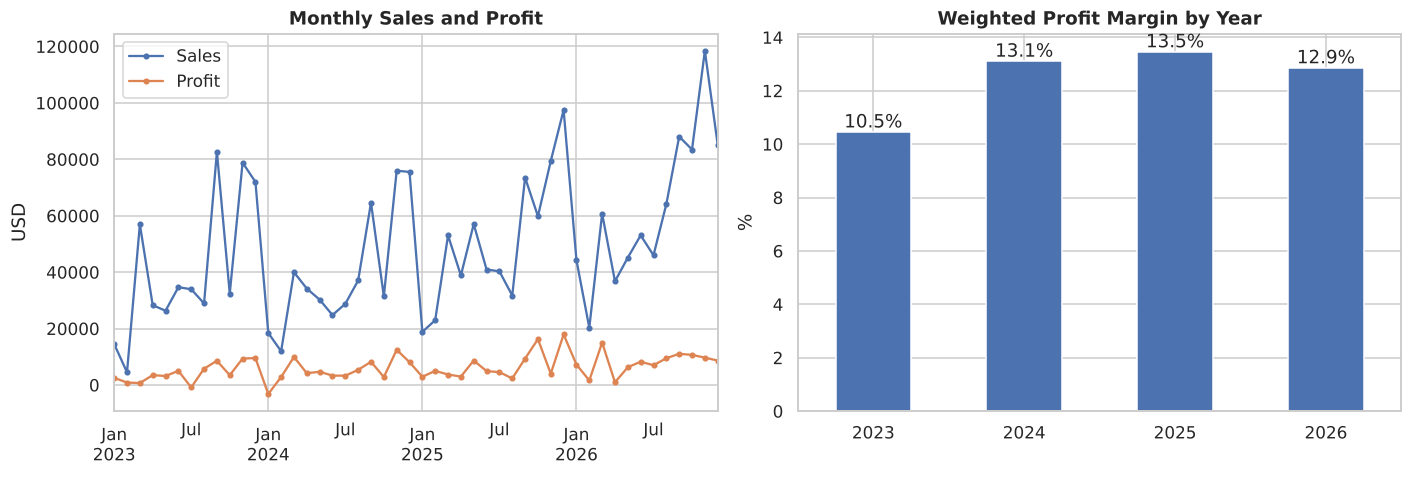

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
m = df.groupby('Month')[['Sales', 'Profit']].sum(); m.index = m.index.to_timestamp()
m.plot(ax=ax[0], marker='o', ms=3); ax[0].set_title('Monthly Sales and Profit'); ax[0].set_xlabel(''); ax[0].set_ylabel('USD')
yearly['Margin %'].plot(kind='bar', ax=ax[1], color='#4c72b0'); ax[1].set_title('Weighted Profit Margin by Year')
ax[1].set_ylabel('%'); ax[1].set_xlabel(''); ax[1].tick_params(axis='x', rotation=0)
for p in ax[1].patches:
    ax[1].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')
plt.tight_layout(); plt.savefig('images/01_trend.png', bbox_inches='tight'); plt.show()

In [ ]:
seasonal = df.groupby(df['Order Date'].dt.month)['Sales'].sum()
(seasonal / seasonal.sum() * 100).round(1).rename('% of total sales by month')

Order Date
1      4.1
2      2.6
3      9.1
4      5.9
5      6.8
6      6.6
7      6.4
8      7.0
9     13.3
10     8.9
11    15.2
12    14.2
Name: % of total sales by month, dtype: float64

**Insight:** sales grew from \$494K (2023) to \$746K (2026), about +51%, and profit nearly doubled (\$51.7K to \$95.9K). Margin rose from 10.5% to a peak of 13.5% in 2025, then slipped to 12.9% in 2026, so growth is outpacing profitability. Sales are strongly seasonal: **Sep, Nov and Dec produce about 43% of total sales**.

## 5. Q2. Categories, sub-categories and regions

### 5.1 Discount, category and region by year

In [ ]:
df.groupby('Year')['Discount'].mean()

Year
2023    0.155758
2024    0.155113
2025    0.154525
2026    0.155999
Name: Discount, dtype: float64

In [ ]:
df.groupby(['Year', 'Category'])[['Sales', 'Profit']].sum()

Sales      Profit
Year Category                                
2023 Furniture        162124.8091   5884.5669
     Office Supplies  154013.9700  23489.3263
     Technology       177901.4330  22310.4025
2024 Furniture        172330.2970   3279.9667
     Office Supplies  137670.2150  25177.8758
     Technology       162992.5190  33563.1270
2025 Furniture        200979.7260   7216.2227
     Office Supplies  186373.6940  35613.2171
     Technology       226580.1600  39835.7620
2026 Furniture        219312.9292   3349.2393
     Office Supplies  253835.4350  41743.0242
     Technology       272419.1670  50834.0841

In [ ]:
region_analysis = df.groupby(['Year', 'Region'])[['Sales', 'Profit']].sum()

region_analysis['Profit Margin'] = (
    region_analysis['Profit'] / region_analysis['Sales']
)

region_analysis

Sales      Profit  Profit Margin
Year Region                                         
2023 Central  103838.1646    539.5534       0.005196
     East     135439.8310  19011.1411       0.140366
     South    103845.8435  11879.1200       0.114392
     West     150916.3730  20254.4812       0.134210
2024 Central  102874.2220  11716.8020       0.113894
     East     157071.4210  21189.0520       0.134901
     South     71359.9805   8318.5940       0.116572
     West     141687.4075  20796.5215       0.146777
2025 Central  148604.6880  20036.7574       0.134833
     East     182749.8740  20602.6331       0.112737
     South     93610.2235  17702.8084       0.189112
     West     188968.7945  24323.0029       0.128714
2026 Central  147853.5982   7572.1942       0.051214
     East     216567.0420  34080.4341       0.157367
     South    122905.8575   8848.9079       0.071997
     West     258241.0335  45424.8114       0.175901

### 5.2 Category and sub-category

In [ ]:
summarize('Category').sort_values('Profit', ascending=False)

,Sales,Profit,Orders,Avg_Discount,Margin %
Category,,,,,
Technology,839893.2790,146543.3756,1560,0.131475,17.447857
Office Supplies,731893.3140,126023.4434,3812,0.156348,17.218827
Furniture,754747.7613,19729.9956,1819,0.172962,2.614118


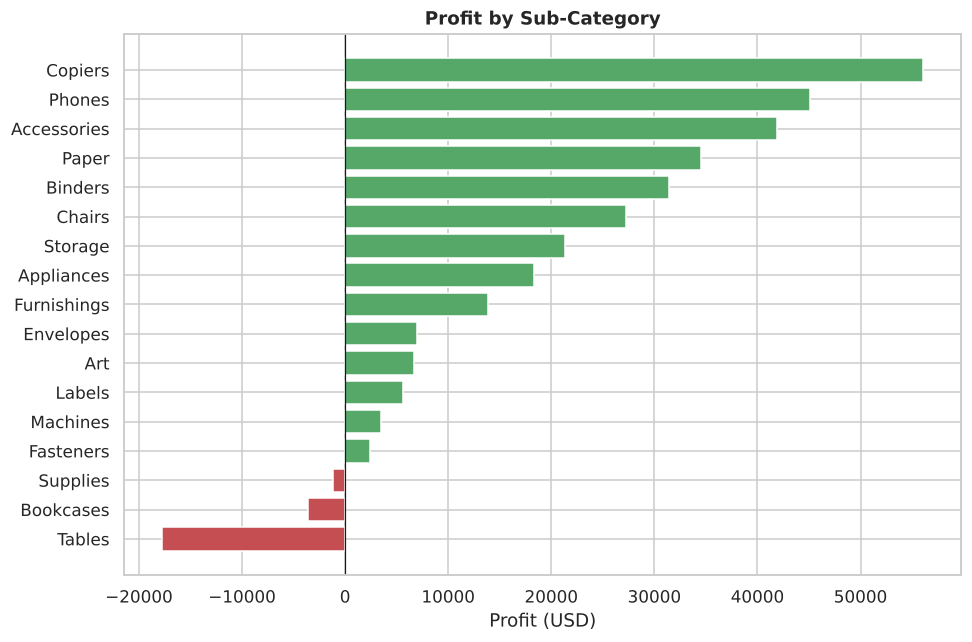

,Sales,Profit,Margin %,Avg_Discount
Sub-Category,,,,
Tables,208020.1820,-17753.2061,-8.534367,0.258129
Bookcases,115361.2043,-3632.0736,-3.148436,0.215259
Supplies,46725.4980,-1171.3945,-2.506971,0.076042
Fasteners,8532.2400,2428.6358,28.464223,0.078603
Machines,189925.0310,3461.9769,1.822812,0.304274
Labels,12695.0420,5572.7780,43.897279,0.070924
Art,27659.0140,6653.1962,24.054351,0.075030
Envelopes,16528.3620,6988.0247,42.278991,0.079688
Furnishings,95598.1260,13891.7430,14.531397,0.138057


In [ ]:
sub = summarize('Sub-Category').sort_values('Profit')
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(sub.index, sub['Profit'], color=['#c44e52' if v < 0 else '#55a868' for v in sub['Profit']]); ax.axvline(0, color='k', lw=.8)
ax.set_title('Profit by Sub-Category'); ax.set_xlabel('Profit (USD)')
plt.tight_layout(); plt.savefig('images/02_subcategory_profit.png', bbox_inches='tight'); plt.show()
sub[['Sales', 'Profit', 'Margin %', 'Avg_Discount']]

**Insight:** Furniture is the problem category. It sells nearly as much as Technology (\$755K vs \$840K) but earns a **2.6% margin**, against about 17% for Technology and Office Supplies. Three sub-categories lose money: **Tables (-\$17.8K)**, **Bookcases (-\$3.6K)** and **Supplies (-\$1.2K)**. Tables and Bookcases are also heavily discounted (26% and 22% on average).

### 5.3 Region and state

,Sales,Profit,Orders,Avg_Discount,Margin %
Region,,,,,
West,739813.6085,110798.8170,1635,0.108946,14.976585
East,691828.1680,94883.2603,1475,0.143436,13.714859
South,391721.9050,46749.4303,822,0.147253,11.934342
Central,503170.6728,39865.3070,1179,0.241002,7.922820


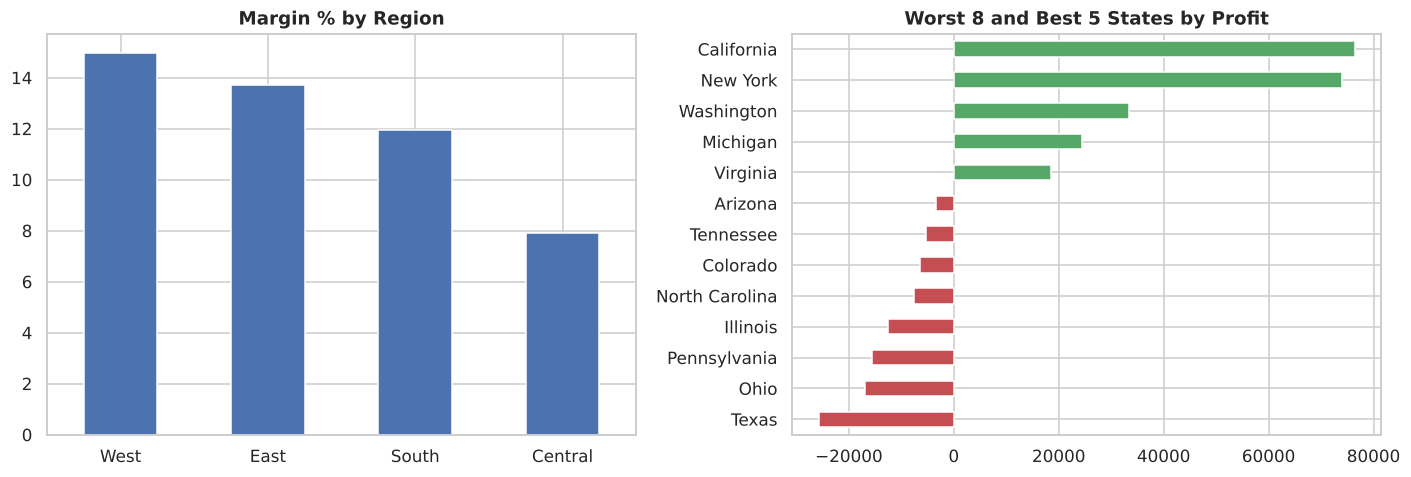

In [ ]:
reg = summarize('Region').sort_values('Profit', ascending=False); display(reg)
state = summarize('State/Province').sort_values('Profit')
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
reg['Margin %'].plot(kind='bar', ax=ax[0], color='#4c72b0'); ax[0].set_title('Margin % by Region'); ax[0].tick_params(axis='x', rotation=0); ax[0].set_xlabel('')
pd.concat([state.head(8), state.tail(5)])['Profit'].plot(kind='barh', ax=ax[1], color=['#c44e52'] * 8 + ['#55a868'] * 5)
ax[1].set_title('Worst 8 and Best 5 States by Profit'); ax[1].set_ylabel('')
plt.tight_layout(); plt.savefig('images/03_region_state.png', bbox_inches='tight'); plt.show()

**Insight:** **Central** earns only a **7.9% margin** vs 15.0% in the West, and its average discount is 24% vs 11%. The weakest states are Texas (-\$25.7K), Ohio (-\$17.0K), Pennsylvania (-\$15.6K) and Illinois (-\$12.6K), all with average discounts of roughly 32% to 39%.

### 5.4 Deep dive: Central region, 2023

Central is the weakest region overall, so its first year is examined at sub-category level.

In [ ]:
central_2023 = df[
    (df['Year'] == 2023) &
    (df['Region'] == 'Central')
]

category_central = central_2023.groupby('Category')[['Sales', 'Profit']].sum()

category_central['Profit Margin'] = (
    category_central['Profit'] / category_central['Sales']
)

category_central

,Sales,Profit,Profit Margin
Category,,,
Furniture,32909.6636,-1105.2241,-0.033584
Office Supplies,37001.6910,622.3076,0.016818
Technology,33926.8100,1022.4699,0.030138


In [ ]:
subcat_central = central_2023.groupby('Sub-Category')[['Sales', 'Profit']].sum()

subcat_central['Profit Margin'] = (
    subcat_central['Profit'] / subcat_central['Sales']
)

subcat_central

,Sales,Profit,Profit Margin
Sub-Category,,,
Accessories,4438.9700,891.2615,0.200781
Appliances,3659.2050,-509.1724,-0.139148
Art,821.9540,187.8420,0.228531
Binders,15870.9380,-1375.9358,-0.086695
Bookcases,1834.0376,-133.6457,-0.072870
Chairs,20754.0520,699.2617,0.033693
Copiers,3269.9260,1034.9780,0.316514
Envelopes,1598.6860,570.8482,0.357073
Fasteners,121.8160,16.0634,0.131866


In [ ]:
loss_products = central_2023.groupby('Sub-Category').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Discount': 'mean'
})

loss_products['Profit Margin'] = (
    loss_products['Profit'] / loss_products['Sales']
)

loss_products = loss_products[
    loss_products['Profit'] < 0
]

loss_products.sort_values(
    by='Profit'
)

,Sales,Profit,Discount,Profit Margin
Sub-Category,,,,
Machines,16292.1620,-2384.6983,0.385714,-0.146371
Tables,7785.4780,-1424.3310,0.326667,-0.182947
Binders,15870.9380,-1375.9358,0.546835,-0.086695
Appliances,3659.2050,-509.1724,0.465217,-0.139148
Furnishings,2536.0960,-246.5091,0.450000,-0.097200
Bookcases,1834.0376,-133.6457,0.222857,-0.072870


In [ ]:
discount_comparison = central_2023.groupby(
    ['Sub-Category', 'Discount']
).agg({
    'Sales': 'sum',
    'Profit': 'sum'
})

discount_comparison

Sales     Profit
Sub-Category Discount                       
Accessories  0.00        983.8500   377.5394
             0.20       3455.1200   513.7221
Appliances   0.00       2584.2800   833.6567
             0.10        480.7710   143.1876
             0.80        594.1540 -1486.0167
Art          0.00        445.3300   136.6319
             0.20        376.6240    51.2101
Binders      0.00      11681.0800  5654.0955
             0.80       4189.8580 -7030.0313
Bookcases    0.00        354.9000    97.2426
             0.30        917.5460  -100.7840
             0.32        561.5916  -130.1043
Chairs       0.00       7117.1700  1584.9787
             0.30      13636.8820  -885.7170
Copiers      0.00        549.9900   274.9950
             0.20       2719.9360   759.9830
Envelopes    0.00        202.1100    93.8903
             0.20       1396.5760   476.9579
Fasteners    0.00         18.5600     5.7214
             0.20        103.2560    10.3420
Furnishings  0.00       1655.2000   381.1510
             0.60        880.8960  -627.6601
Labels       0.00        831.9600   407.9588
             0.20        216.5120    73.5920
Machines     0.30        574.9100   156.0470
             0.40      15717.2520 -2540.7453
Paper        0.00        705.6000   336.0480
             0.20       1641.1760   560.1591
Phones       0.00       1734.6800   421.4913
             0.20       8191.0720  1059.4374
Storage      0.00       5692.2500   744.1585
             0.20       5401.1360  -399.7191
Supplies     0.00        357.9300     7.1586
             0.20         82.5280     3.3063
Tables       0.00       1614.6200   218.3988
             0.30       4421.7180  -544.8099
             0.50       1749.1400 -1097.9199

**Takeaway:** in 2023 Central earned only **\$540 profit on \$104K of sales (0.5% margin)** with a 26% average discount. Six sub-categories lost money, led by Machines (-\$2.4K), Tables (-\$1.4K) and Binders (-\$1.4K, with a 55% average discount). Central's result also swings from year to year (0.5%, 11.4%, 13.5%, 5.1%), which points to inconsistent discounting rather than a structural cost problem.

## 6. Q3. Does discounting hurt profit?

In [ ]:
df['Discount Band'] = pd.cut(df['Discount'], [-0.01, 0, 0.1, 0.2, 0.3, 0.4, 0.5, 1],
                             labels=['0%', '1-10%', '11-20%', '21-30%', '31-40%', '41-50%', '>50%'])
disc = summarize('Discount Band'); disc

,Sales,Profit,Orders,Avg_Discount,Margin %
Discount Band,,,,,
0%,1.105324e+06,326718.5872,2714,0.000000,29.558632
1-10%,5.495250e+04,9099.9700,91,0.100000,16.559702
11-20%,8.014979e+05,92498.9432,2469,0.199308,11.540759
21-30%,1.044741e+05,-10513.4456,214,0.300000,-10.063211
31-40%,1.309912e+05,-25477.5119,212,0.390769,-19.449786
41-50%,6.440351e+04,-22999.5392,74,0.492857,-35.711622
>50%,6.489135e+04,-77030.1891,701,0.717391,-118.706402


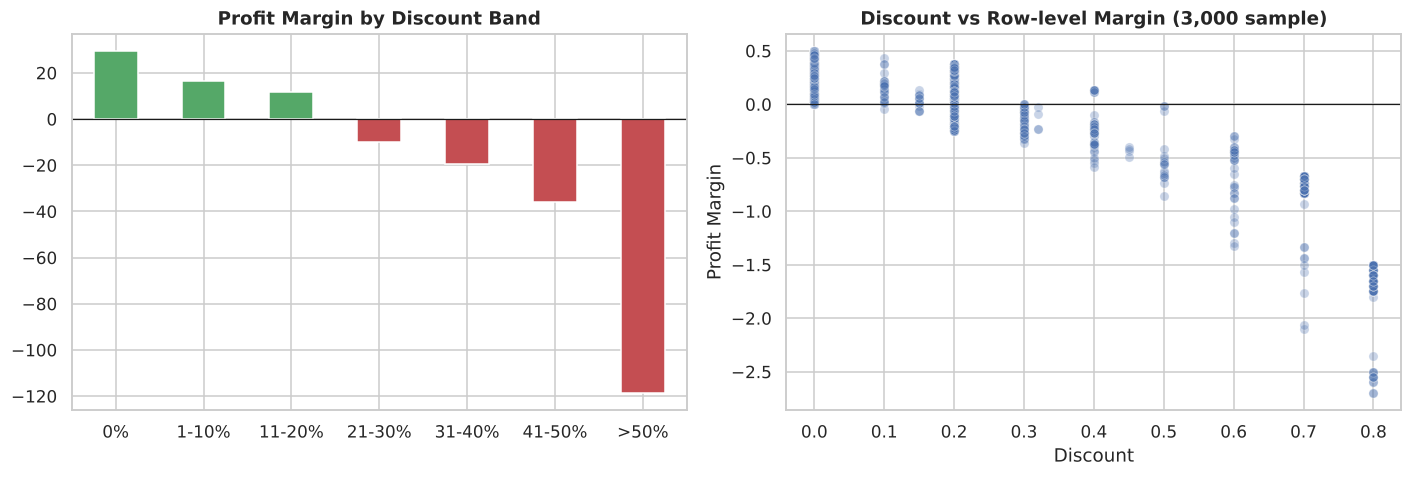

Correlation Discount vs Profit Margin: -0.865


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
disc['Margin %'].plot(kind='bar', ax=ax[0], color=['#55a868' if v > 0 else '#c44e52' for v in disc['Margin %']])
ax[0].axhline(0, color='k', lw=.8); ax[0].set_title('Profit Margin by Discount Band'); ax[0].tick_params(axis='x', rotation=0); ax[0].set_xlabel('')
sns.scatterplot(data=df.sample(3000, random_state=1), x='Discount', y='Profit Margin', alpha=.3, ax=ax[1])
ax[1].axhline(0, color='k', lw=.8); ax[1].set_title('Discount vs Row-level Margin (3,000 sample)')
plt.tight_layout(); plt.savefig('images/04_discount.png', bbox_inches='tight'); plt.show()
print('Correlation Discount vs Profit Margin:', round(df['Discount'].corr(df['Profit Margin']), 3))

In [ ]:
bad = df[df['Discount'] > 0.2]
print(f"Lines with discount >20%: {len(bad)/len(df):.1%} of lines, {bad['Sales'].sum()/tot_s:.1%} of sales")
print(f"Their total profit: ${bad['Profit'].sum():,.0f}")
print(f"Total profit if those lines were break-even: ${tot_p - bad['Profit'].sum():,.0f} ({-bad['Profit'].sum()/tot_p:+.0%} vs actual)")

Lines with discount >20%: 13.9% of lines, 15.7% of sales
Their total profit: $-136,021
Total profit if those lines were break-even: $428,318 (+47% vs actual)


**Insight:** this is the single biggest finding. Margin falls steadily as discount rises: **29.6%** with no discount, **11.5%** at 11-20%, then **negative from 21% upward**. Lines discounted above 20% are 14% of all lines and lose roughly **\$136K** combined. Bringing them to break-even would lift total profit by about **47%**.

## 7. Q4. Customers and segments

### 7.1 Segments and top customers

In [ ]:
seg = summarize('Segment'); display(seg)
cust = df.groupby(['Customer ID', 'Customer Name']).agg(Sales=('Sales', 'sum'), Profit=('Profit', 'sum'), Orders=('Order ID', 'nunique')).reset_index()
cust['Margin %'] = cust['Profit'] / cust['Sales'] * 100
print('Customers:', len(cust), '| unprofitable:', (cust['Profit'] < 0).sum(), f"({(cust['Profit'] < 0).mean():.0%})")
cust.sort_values('Sales', ascending=False).head(10)

,Sales,Profit,Orders,Avg_Discount,Margin %
Segment,,,,,
Consumer,1.170660e+06,136371.4463,2628,0.157605,11.649110
Corporate,7.158061e+05,94249.6400,1552,0.156489,13.166923
Home Office,4.400684e+05,61675.7283,931,0.147082,14.015031


Customers: 804 | unprofitable: 159 (20%)


,Customer ID,Customer Name,Sales,Profit,Orders,Margin %
711,SM-20320,Sean Miller,25043.050,-1980.7393,5,-7.909337
752,TC-20980,Tamara Chand,19052.218,8981.3239,5,47.140569
632,RB-19360,Raymond Buch,15117.339,6976.0959,6,46.146322
741,TA-21385,Tom Ashbrook,14595.620,4703.7883,4,32.227396
6,AB-10105,Adrian Barton,14473.571,5444.8055,10,37.618950
443,KL-16645,Ken Lonsdale,14175.229,806.8550,12,5.692007
680,SC-20095,Sanjit Chand,14142.334,5757.4119,9,40.710479
328,HL-15040,Hunter Lopez,12873.298,5622.4292,6,43.675127
694,SE-20110,Sanjit Engle,12209.438,2650.6769,11,21.710065
132,CC-12370,Christopher Conant,12129.072,2177.0493,5,17.949018


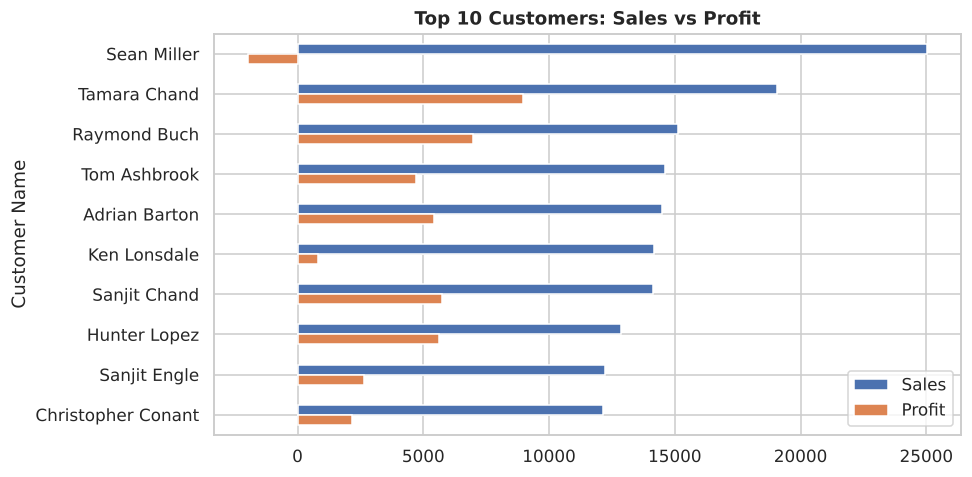

In [ ]:
top = cust.nlargest(10, 'Sales').set_index('Customer Name')[['Sales', 'Profit']]
top.plot(kind='barh', figsize=(9, 4.5)); plt.title('Top 10 Customers: Sales vs Profit'); plt.gca().invert_yaxis()
plt.tight_layout(); plt.savefig('images/05_top_customers.png', bbox_inches='tight'); plt.show()

### 7.2 RFM segmentation (Recency, Frequency, Monetary)

In [ ]:
snap = df['Order Date'].max() + pd.Timedelta(days=1)
rfm = df.groupby('Customer ID').agg(Recency=('Order Date', lambda x: (snap - x.max()).days),
                                    Frequency=('Order ID', 'nunique'), Monetary=('Sales', 'sum'))
for c, asc in [('Recency', False), ('Frequency', True), ('Monetary', True)]:
    rfm[c[0]] = pd.qcut(rfm[c].rank(method='first'), 4, labels=[1, 2, 3, 4] if asc else [4, 3, 2, 1]).astype(int)
rfm['Score'] = rfm[['R', 'F', 'M']].sum(axis=1)
rfm['Tier'] = pd.cut(rfm['Score'], [0, 5, 8, 12], labels=['At risk', 'Regular', 'Champion'])
rfm.groupby('Tier', observed=True).agg(Customers=('Monetary', 'size'), Avg_Spend=('Monetary', 'mean'), Avg_Orders=('Frequency', 'mean'))

,Customers,Avg_Spend,Avg_Orders
Tier,,,
At risk,201,918.053716,3.696517
Regular,286,2518.357337,5.723776
Champion,317,4485.032679,8.634069


**Insight:** Consumer is the largest segment (50% of sales) but has the lowest margin of the three segments (11.7%, vs 13.2% for Corporate and 14.0% for Home Office). The top customer by sales, **Sean Miller (\$25K)**, is **unprofitable (-\$2K)**, and **159 of 804 customers (20%)** cost the business money. "Best customer" should be judged by profit, not revenue. RFM scoring splits customers into 317 Champions, 286 Regular and 201 At-risk, which gives a ready list for retention work.

## 8. Q5. Does shipping matter?

In [ ]:
ship = df.groupby('Ship Mode').agg(Avg_Ship_Days=('Ship Days', 'mean'), Orders=('Order ID', 'nunique'),
                                   Sales=('Sales', 'sum'), Profit=('Profit', 'sum'))
ship['Margin %'] = ship['Profit'] / ship['Sales'] * 100
ship['Share of orders %'] = ship['Orders'] / ship['Orders'].sum() * 100
ship.sort_values('Avg_Ship_Days')

,Avg_Ship_Days,Orders,Sales,Profit,Margin %,Share of orders %
Ship Mode,,,,,,
Same Day,0.043876,266,1.292720e+05,16160.7480,12.501357,5.204461
First Class,2.182171,795,3.517507e+05,49012.7242,13.933936,15.554686
Second Class,3.237999,982,4.666711e+05,58962.1329,12.634622,19.213461
Standard Class,4.995425,3068,1.378841e+06,168161.2095,12.195842,60.027392


**Insight:** shipping mode has little effect on profitability (margins range from 12.2% to 13.9%). Standard Class is about 59% of sales and takes 5 days on average. Delivery speed is not a profit lever here, so it should not be a priority.

## 9. Export processed data

The original data needed no cleaning, so the export is the raw data plus the engineered columns (`Ship Days`, `Year`, `Month`, `Profit Margin`, `Discount Band`). Use it as the source for a Tableau or Power BI dashboard.

In [ ]:
export = df.copy()
export['Month'] = export['Month'].astype(str)
export['Discount Band'] = export['Discount Band'].astype(str)
export.to_csv('data/superstore_processed.csv', index=False)
print(export.shape)

(10194, 26)


## 10. Recommendations and limitations

| Priority | Finding | Recommendation | Expected impact |
|:-:|---------|----------------|-----------------|
| 1 | Discounts above 20% always lose money | Cap discounts at 20% and require approval above that | Removes about \$136K of losses |
| 2 | Furniture margin is 2.6%; Tables and Bookcases lose money | Review pricing and supplier cost; stop discounting Tables below cost | Turns about \$21K of loss into profit |
| 3 | Central margin is 7.9% with a 24% average discount | Align Central's discount policy with West and East | Closes the gap to the 14-15% margin of other regions |
| 4 | 20% of customers are unprofitable | Report customer profit, not just sales, in account reviews | Better account decisions |
| 5 | Sep, Nov and Dec drive 43% of sales | Plan inventory and staffing for the peak; avoid deep peak-season discounts | Protects margin at highest volume |

### Limitations
- The data has no product cost, marketing cost or returns, so profit is taken as reported.
- US only; no customer demographics beyond segment.
- Findings show association, not proof of cause (for example, discounts may be given to move slow stock).

### Next steps
- Build an interactive dashboard (Tableau Public or Power BI) from `data/superstore_processed.csv`.
- Test a simulated 20% discount cap to estimate the effect on sales volume as well as profit.